# Pose classifier evaluation

Compares every exported experiment (landmark, landmark_aug, image_transfer,
image_finetune) on the same held-out validation set: accuracy, latency, a
confusion matrix, and per-class precision/recall/F1.

Predictions come from `training.benchmark.evaluate_all`, which reproduces each
model's exact validation split (the same seed the checkpoint was selected on) and
runs its exported ONNX. A model that has not been trained and exported is skipped.

Train and export the experiments first if they are missing:

```bash
python -m training.extract_landmarks
python -m training.extract_landmarks_aug
python -m training.experiments.landmark_mlp
python -m training.experiments.landmark_aug
python -m training.experiments.image_transfer
python -m training.experiments.image_finetune
python -m training.export landmark
python -m training.export landmark_aug
python -m training.export image_transfer
python -m training.export image_finetune
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from training import benchmark

# one held-out evaluation per exported model (predictions + probs + latency)
evals = benchmark.evaluate_all()
by_name = {e.name: e for e in evals}
print("evaluated:", ", ".join(by_name) or "nothing (train and export first)")

evaluated: landmark, landmark_aug, image_transfer, image_finetune


## Accuracy and latency

Top-1 accuracy on the held-out validation set and per-inference latency (p50 and
p95, in milliseconds). The landmark models score on landmark features, the image
models on preprocessed frames, but all on the same held-out fold, so the accuracy
numbers compare directly.

,val_acc,p50_ms,p95_ms,n_val
model,,,,
landmark_aug,0.938,0.01,0.01,64
landmark,0.908,0.01,0.01,65
image_finetune,0.862,2.05,2.13,65
image_transfer,0.769,2.01,2.13,65


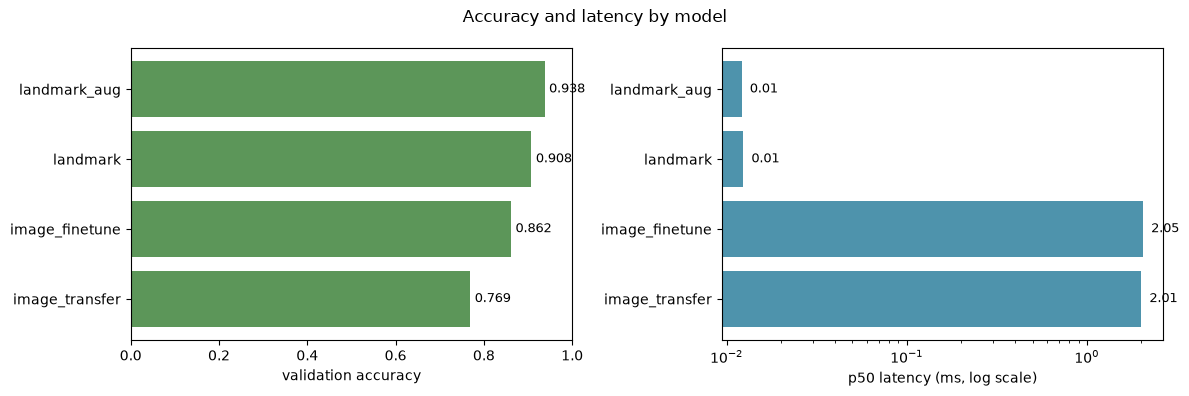

In [2]:
summary = pd.DataFrame(
    [
        {
            "model": e.name,
            "val_acc": e.val_accuracy,
            "p50_ms": e.latency_p50_ms,
            "p95_ms": e.latency_p95_ms,
            "n_val": len(e.y_true),
        }
        for e in evals
    ]
).set_index("model").sort_values("val_acc", ascending=False)
display(summary.style.format({"val_acc": "{:.3f}", "p50_ms": "{:.2f}", "p95_ms": "{:.2f}"}))

fig, (ax_acc, ax_lat) = plt.subplots(1, 2, figsize=(12, 4))
ordered = summary.iloc[::-1]  # lowest at the bottom for a top-down bar chart

ax_acc.barh(ordered.index, ordered["val_acc"], color="#5c9659")
ax_acc.set_xlim(0, 1)
ax_acc.set_xlabel("validation accuracy")
for i, v in enumerate(ordered["val_acc"]):
    ax_acc.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

ax_lat.barh(ordered.index, ordered["p50_ms"], color="#4e93ac")
ax_lat.set_xlabel("p50 latency (ms, log scale)")
ax_lat.set_xscale("log")
for i, v in enumerate(ordered["p50_ms"]):
    ax_lat.text(v, i, f"  {v:.2f}", va="center", fontsize=9)

fig.suptitle("Accuracy and latency by model")
plt.tight_layout()
plt.show()

## Confusion matrices

Rows are the true pose, columns the predicted. A clean diagonal means the model
separates the poses. Off-diagonal cells show which poses get confused, usually
ones with similar body geometry. One matrix per model, on a shared class order.

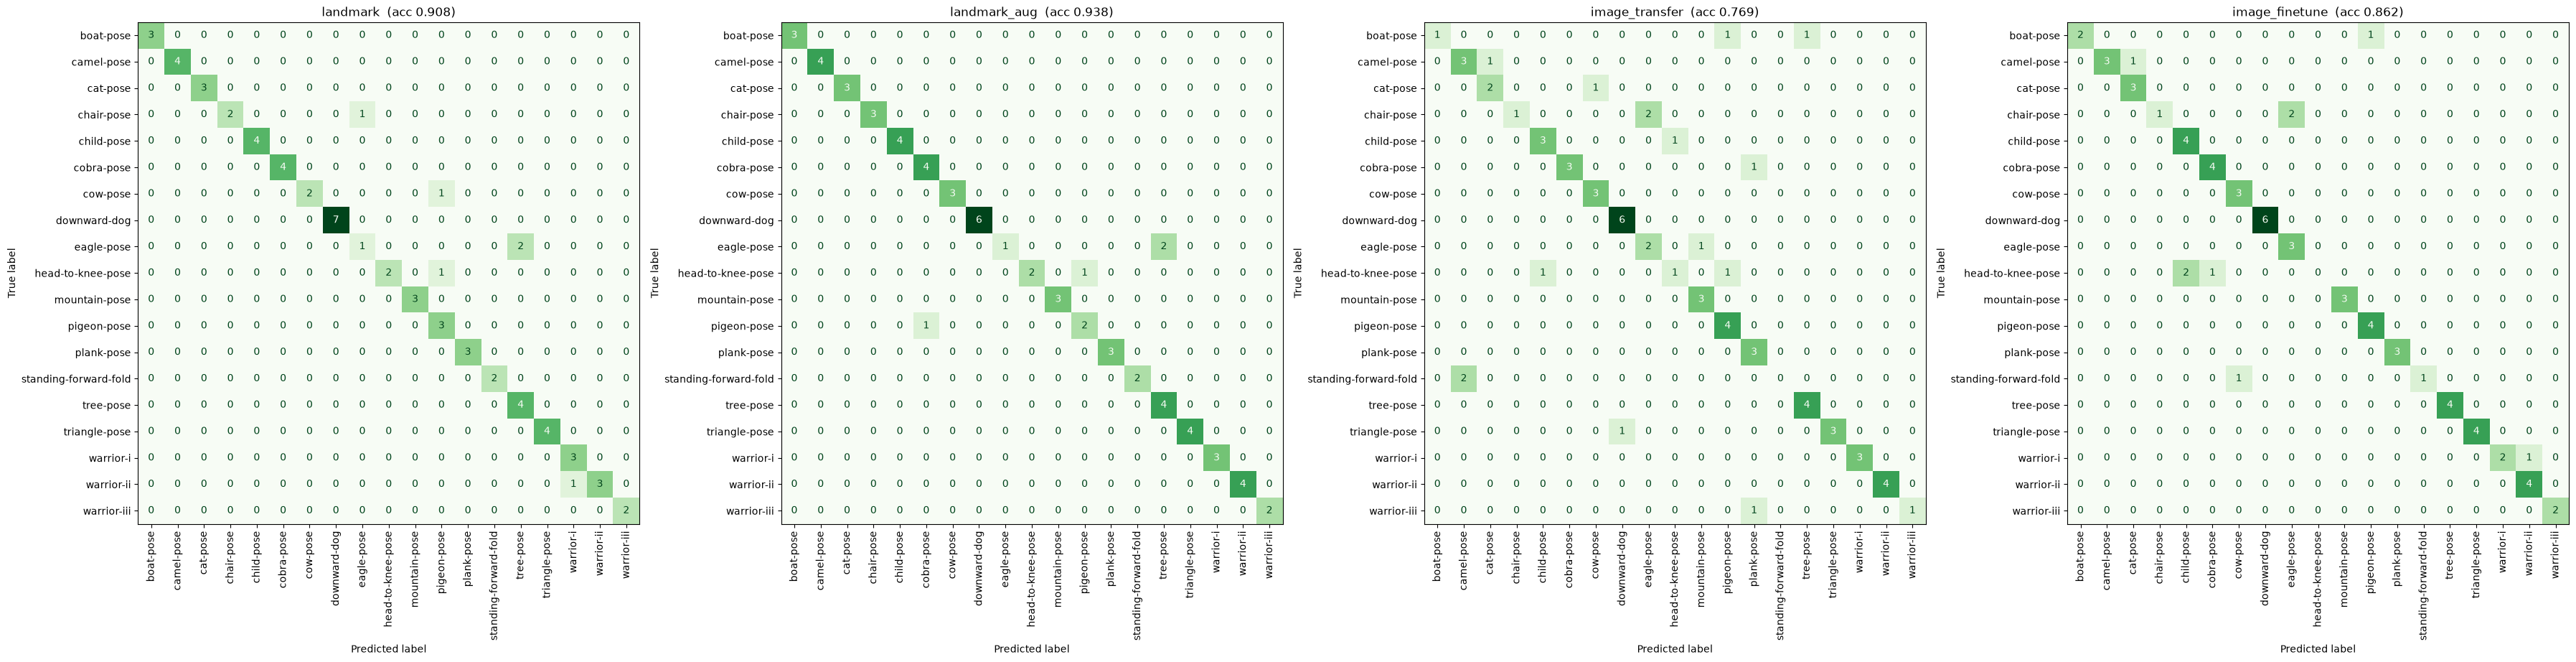

In [3]:
n = len(evals)
fig, axes = plt.subplots(1, n, figsize=(9 * n, 9), squeeze=False)
for ax, e in zip(axes[0], evals):
    cm = confusion_matrix(e.y_true, e.y_pred, labels=range(len(e.labels)))
    ConfusionMatrixDisplay(cm, display_labels=e.labels).plot(
        ax=ax, cmap="Greens", colorbar=False, xticks_rotation=90
    )
    ax.set_title(f"{e.name}  (acc {e.val_accuracy:.3f})")
plt.tight_layout()
plt.show()

## Per-class precision, recall, F1

One report per model. Support is small per class (val is ~20% of a few hundred
photos), so treat a single miss as one sample, not a trend. Low-support classes
swing hard on one error.

In [4]:
for e in evals:
    report = classification_report(
        e.y_true, e.y_pred, labels=range(len(e.labels)),
        target_names=e.labels, output_dict=True, zero_division=0,
    )
    df = pd.DataFrame(report).T
    df["support"] = df["support"].astype(int)
    print(f"{e.name} (acc {e.val_accuracy:.3f})")
    display(
        df.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}"})
    )

landmark (acc 0.908)


,precision,recall,f1-score,support
boat-pose,1.000,1.000,1.000,3
camel-pose,1.000,1.000,1.000,4
cat-pose,1.000,1.000,1.000,3
chair-pose,1.000,0.667,0.800,3
child-pose,1.000,1.000,1.000,4
cobra-pose,1.000,1.000,1.000,4
cow-pose,1.000,0.667,0.800,3
downward-dog,1.000,1.000,1.000,7
eagle-pose,0.500,0.333,0.400,3
head-to-knee-pose,1.000,0.667,0.800,3


landmark_aug (acc 0.938)


,precision,recall,f1-score,support
boat-pose,1.000,1.000,1.000,3
camel-pose,1.000,1.000,1.000,4
cat-pose,1.000,1.000,1.000,3
chair-pose,1.000,1.000,1.000,3
child-pose,1.000,1.000,1.000,4
cobra-pose,0.800,1.000,0.889,4
cow-pose,1.000,1.000,1.000,3
downward-dog,1.000,1.000,1.000,6
eagle-pose,1.000,0.333,0.500,3
head-to-knee-pose,1.000,0.667,0.800,3


image_transfer (acc 0.769)


,precision,recall,f1-score,support
boat-pose,1.000,0.333,0.500,3
camel-pose,0.600,0.750,0.667,4
cat-pose,0.667,0.667,0.667,3
chair-pose,1.000,0.333,0.500,3
child-pose,0.750,0.750,0.750,4
cobra-pose,1.000,0.750,0.857,4
cow-pose,0.750,1.000,0.857,3
downward-dog,0.857,1.000,0.923,6
eagle-pose,0.500,0.667,0.571,3
head-to-knee-pose,0.500,0.333,0.400,3


image_finetune (acc 0.862)


,precision,recall,f1-score,support
boat-pose,1.000,0.667,0.800,3
camel-pose,1.000,0.750,0.857,4
cat-pose,0.750,1.000,0.857,3
chair-pose,1.000,0.333,0.500,3
child-pose,0.667,1.000,0.800,4
cobra-pose,0.800,1.000,0.889,4
cow-pose,0.750,1.000,0.857,3
downward-dog,1.000,1.000,1.000,6
eagle-pose,0.600,1.000,0.750,3
head-to-knee-pose,0.000,0.000,0.000,3


## Most confident mistakes

Per model, the misclassifications ranked by the model's confidence in the wrong
answer. A wrong call made with high probability points at two poses the features
blur together, worth more photos or a look at the landmark quality.

In [5]:
for e in evals:
    wrong = np.where(e.y_pred != e.y_true)[0]
    wrong = sorted(wrong, key=lambda i: e.probs[i, e.y_pred[i]], reverse=True)
    print(f"{e.name}: {len(wrong)} misclassified of {len(e.y_true)}")
    if not wrong:
        continue
    mistakes = pd.DataFrame(
        [
            {
                "true": e.labels[e.y_true[i]],
                "predicted": e.labels[e.y_pred[i]],
                "p_pred": e.probs[i, e.y_pred[i]],
                "p_true": e.probs[i, e.y_true[i]],
            }
            for i in wrong
        ]
    )
    display(mistakes.style.format({"p_pred": "{:.2f}", "p_true": "{:.2f}"}).hide(axis="index"))

landmark: 6 misclassified of 65


true,predicted,p_pred,p_true
head-to-knee-pose,pigeon-pose,0.95,0.00
eagle-pose,tree-pose,0.68,0.09
cow-pose,pigeon-pose,0.56,0.32
eagle-pose,tree-pose,0.49,0.14
chair-pose,eagle-pose,0.41,0.29
warrior-ii,warrior-i,0.38,0.20


landmark_aug: 4 misclassified of 64


true,predicted,p_pred,p_true
head-to-knee-pose,pigeon-pose,0.86,0.00
eagle-pose,tree-pose,0.70,0.04
eagle-pose,tree-pose,0.55,0.08
pigeon-pose,cobra-pose,0.53,0.03


image_transfer: 15 misclassified of 65


true,predicted,p_pred,p_true
triangle-pose,downward-dog,0.98,0.00
chair-pose,eagle-pose,0.92,0.01
cat-pose,cow-pose,0.89,0.07
child-pose,head-to-knee-pose,0.77,0.20
boat-pose,tree-pose,0.76,0.08
head-to-knee-pose,child-pose,0.64,0.30
standing-forward-fold,camel-pose,0.63,0.01
camel-pose,cat-pose,0.55,0.27
chair-pose,eagle-pose,0.54,0.00
warrior-iii,plank-pose,0.51,0.24


image_finetune: 9 misclassified of 65


true,predicted,p_pred,p_true
head-to-knee-pose,child-pose,0.97,0.03
head-to-knee-pose,child-pose,0.91,0.06
chair-pose,eagle-pose,0.69,0.03
chair-pose,eagle-pose,0.67,0.02
head-to-knee-pose,cobra-pose,0.62,0.03
camel-pose,cat-pose,0.61,0.33
warrior-i,warrior-ii,0.52,0.16
boat-pose,pigeon-pose,0.43,0.11
standing-forward-fold,cow-pose,0.26,0.16


## Dataset class balance

How many usable photos each pose has. Thin classes are the ones to grow next.

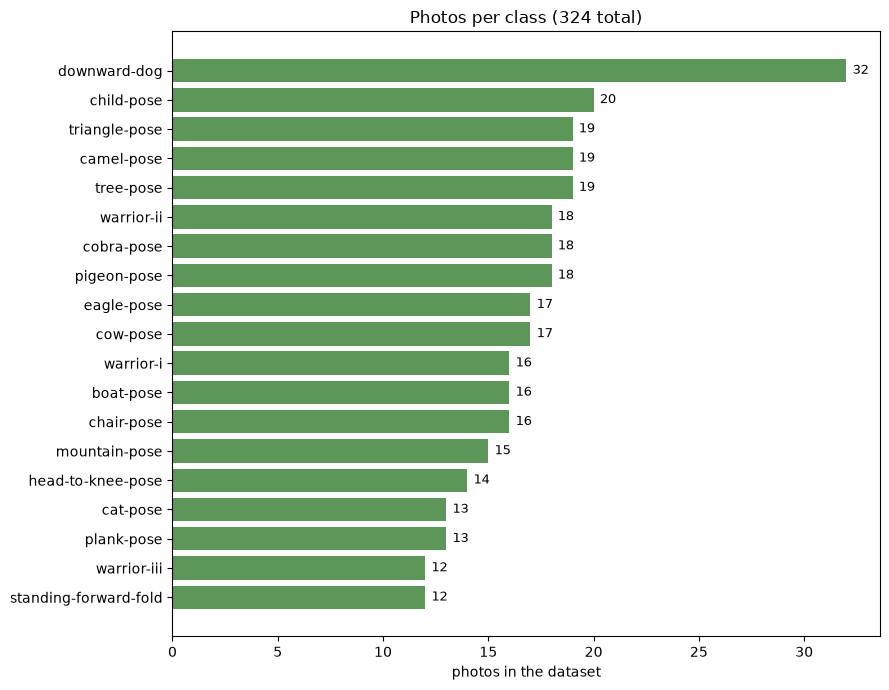

In [6]:
from common.dataset import pose_folders

counts = pd.Series(
    {label: len(files) for label, files in pose_folders()}, name="photos"
).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(counts.index, counts.values, color="#5c9659")
ax.set_xlabel("photos in the dataset")
ax.set_title(f"Photos per class ({int(counts.sum())} total)")
for i, v in enumerate(counts.values):
    ax.text(v + 0.3, i, str(int(v)), va="center", fontsize=9)
plt.tight_layout()
plt.show()